# SAM 3D Body pilot: does a stronger pose model help where MediaPipe struggles?

The person-gap experiments left two problems untouched: arm abduction, and views where the exercising
(right) arm is on the far side of the body from the camera. Both are where MediaPipe is least confident.
This pilot runs SAM 3D Body on a small sample of arm-abduction repetitions and asks, without training any
classifier:

1. **Consistency.** Three synchronized cameras film the same repetition, so a joint angle should be the
   same from every camera. How much do the cameras disagree, for each pose model?
2. **Separability.** Do simple, known indicators of two errors (bent arm, arm forward) separate correct
   from incorrect repetitions better with one pose model than the other, especially in far-side views?

Sample: 48 repetitions (2 correct, 1 bent-arm, 1 arm-forward for each of the four development participants
at orientations 0°, 45° and 90°), each from all three cameras. The held-out test participant is not used.
SAM 3D Body was run in body-only mode on every third frame, with the person box taken from the MediaPipe
landmarks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from rehab26.data import DATA_DIR, load_dataset
from rehab26.features import joint_angle, vector_angle
from rehab26.sam3d import load_sam3d

FIG = "../docs/figures"
pd.set_option("display.width", 200)

X, meta = load_dataset(n_frames=64)
P_sam, idx = load_sam3d(DATA_DIR / "sam3d/pilot", n_frames=64)
rows = meta.reset_index().merge(idx, on=["rep_id", "cam"]).sort_values(["rep_id", "cam"]).reset_index(drop=True)
order = idx.set_index(["rep_id", "cam"]).assign(i=np.arange(len(idx))).loc[list(zip(rows.rep_id, rows.cam)), "i"].values
P = {"MediaPipe": X[rows["index"].values, :, :, :3], "SAM 3D Body": P_sam[order]}
vis_right_arm = X[rows["index"].values][:, :, [12, 14, 16], 3].mean(axis=(1, 2))
rows["vis_right_arm"] = vis_right_arm
print("sequences:", len(rows), "| repetitions:", rows.rep_id.nunique(), "| participants:", sorted(rows.person.unique()))
print("SAM 3D Body frames:", int(rows.n_samples.sum()), "| failed frames:", int(rows.failed.sum()),
      "| mean inference %.3f s/frame" % rows.seconds.mean())
display(rows.groupby("view").agg(sequences=("rep_id", "size"), mediapipe_right_arm_visibility=("vis_right_arm", "mean")).round(2).T)

sequences: 144 | repetitions: 48 | participants: ['Honza', 'Mima', 'Petra', 'Terka']
SAM 3D Body frames: 5073 | failed frames: 0 | mean inference 0.166 s/frame


view,-90,-45,0,45,90
sequences,16.00,32.00,48.00,32.00,16.00
mediapipe_right_arm_visibility,0.43,0.83,0.99,0.99,0.95


## 1. Angles that should not depend on the camera

Four angles computed the same way from both pose sources: elbow flexion and shoulder elevation
(hip-shoulder-elbow) for the exercising right arm and for the resting left arm.

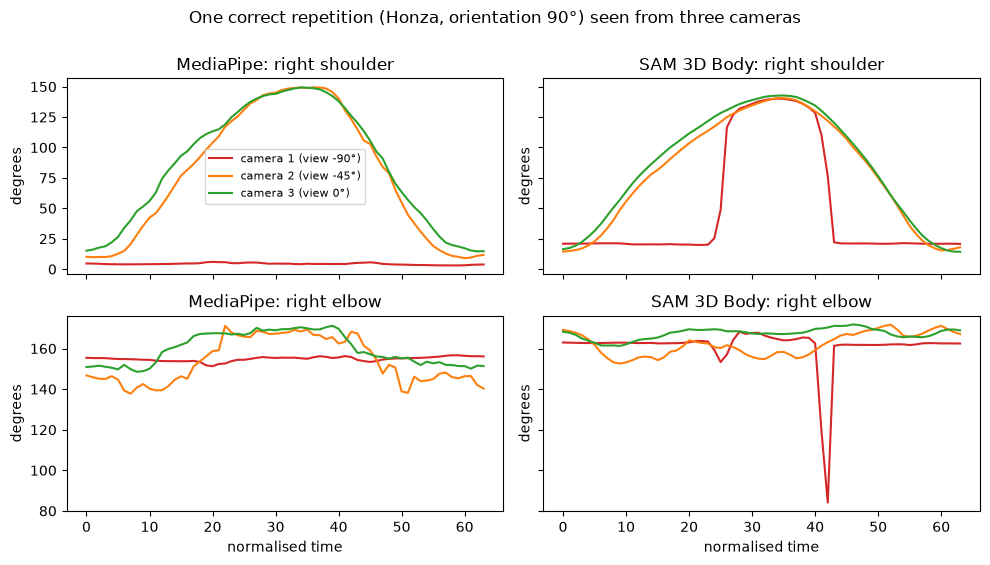

In [2]:
ANGLES = {
    "right elbow": lambda p: joint_angle(p[:, :, 12], p[:, :, 14], p[:, :, 16]),
    "right shoulder": lambda p: joint_angle(p[:, :, 24], p[:, :, 12], p[:, :, 14]),
    "left elbow": lambda p: joint_angle(p[:, :, 11], p[:, :, 13], p[:, :, 15]),
    "left shoulder": lambda p: joint_angle(p[:, :, 23], p[:, :, 11], p[:, :, 13]),
}
A = {src: {name: fn(p) for name, fn in ANGLES.items()} for src, p in P.items()}     # each (N, T) in degrees

# One repetition at orientation 90: camera 1 sees the far side (-90), camera 3 is frontal (0)
ex = rows[(rows.orientation == 90) & (rows.error == "correct")].rep_id.iloc[0]
sel = rows.index[rows.rep_id == ex]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True, sharey="row")
for r, name in enumerate(["right shoulder", "right elbow"]):
    for c, src in enumerate(P):
        ax = axes[r, c]
        for i, color in zip(sel, ("tab:red", "tab:orange", "tab:green")):
            ax.plot(A[src][name][i], color=color, label=f"camera {rows.cam[i]} (view {rows['view'][i]}°)")
        ax.set_title(f"{src}: {name}"); ax.set_ylabel("degrees")
axes[0, 0].legend(fontsize=8); axes[1, 0].set_xlabel("normalised time"); axes[1, 1].set_xlabel("normalised time")
fig.suptitle(f"One correct repetition ({rows.person[sel[0]]}, orientation 90°) seen from three cameras", y=1.0)
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p4_example.png", dpi=150); plt.show()

## 2. Cross-camera disagreement

For every repetition and angle, the disagreement is the range across the three cameras (largest minus
smallest), averaged over the repetition. Lower is better. Agreement is not the same as accuracy: there is
no motion-capture reference here, so a model could agree with itself and still be wrong.

In [3]:
def disagreement(angle):                       # angle: (N, T) aligned with rows
    out = {}
    for rep, g in rows.groupby("rep_id"):
        a = angle[g.index.values]              # (3, T)
        out[rep] = (a.max(0) - a.min(0)).mean()
    return pd.Series(out)

dis = pd.DataFrame({(src, name): disagreement(A[src][name]) for src in P for name in ANGLES})
summary = pd.DataFrame({src: dis[src].mean() for src in P})
summary["SAM better in (share of reps)"] = [(dis["SAM 3D Body"][n] < dis["MediaPipe"][n]).mean() for n in ANGLES]
print("Mean range across the three cameras (degrees):")
display(summary.round(2))

rep_info = rows.drop_duplicates("rep_id").set_index("rep_id")
by_orient = pd.concat({src: dis[src].groupby(rep_info.orientation).mean() for src in P}, axis=1)
print("By participant orientation (at 90° one camera sees the far side at -90° and another at -45°):")
display(by_orient.round(1))

Mean range across the three cameras (degrees):


,MediaPipe,SAM 3D Body,SAM better in (share of reps)
right elbow,18.639999,9.29,0.94
right shoulder,31.620001,10.85,1.00
left elbow,20.870001,8.49,0.96
left shoulder,26.530001,9.58,0.96


By participant orientation (at 90° one camera sees the far side at -90° and another at -45°):


MediaPipe                                         SAM 3D Body                                        
            right elbow right shoulder left elbow left shoulder right elbow right shoulder left elbow left shoulder
orientation                                                                                                        
0             19.000000      15.500000  23.000000     53.400002         7.5            5.9       14.1          20.5
45            17.200001      14.100000  24.700001     11.800000         8.0            6.3        6.3           4.5
90            19.700001      65.199997  14.900000     14.400000        12.5           20.4        5.0           3.7

Mean absolute difference from the best-view camera (degrees), by this camera's viewing angle:


source               MediaPipe  SAM 3D Body
angle          view                        
right elbow    -90   15.300000         10.4
               -45   10.800000          5.7
                0    13.700000          5.0
                45   13.100000          4.8
right shoulder -90   63.599998         19.9
               -45   10.300000          4.4
                0    10.500000          4.1
                45   10.800000          3.4

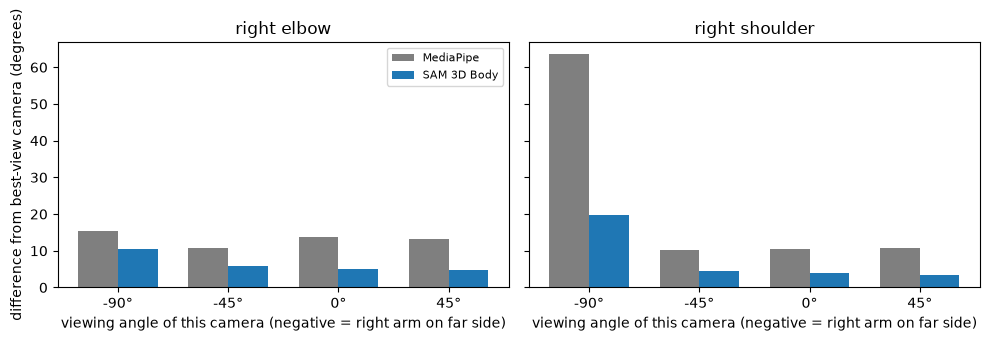

In [4]:
# How far is each camera from the camera with the best view of the right arm (largest viewing angle)?
recs = []
for rep, g in rows.groupby("rep_id"):
    ref = g["view"].idxmax()
    for i in g.index:
        if i == ref:
            continue
        for src in P:
            for name in ("right elbow", "right shoulder"):
                recs.append(dict(source=src, angle=name, view=rows["view"][i],
                                 diff=np.abs(A[src][name][i] - A[src][name][ref]).mean()))
dev = pd.DataFrame(recs).groupby(["angle", "view", "source"])["diff"].mean().unstack()
print("Mean absolute difference from the best-view camera (degrees), by this camera's viewing angle:")
display(dev.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, ("right elbow", "right shoulder")):
    d = dev.loc[name]
    xs = np.arange(len(d))
    ax.bar(xs - 0.18, d["MediaPipe"], 0.36, color="tab:gray", label="MediaPipe")
    ax.bar(xs + 0.18, d["SAM 3D Body"], 0.36, color="tab:blue", label="SAM 3D Body")
    ax.set_xticks(xs); ax.set_xticklabels([f"{v}°" for v in d.index]); ax.set_title(name)
    ax.set_xlabel("viewing angle of this camera (negative = right arm on far side)")
axes[0].set_ylabel("difference from best-view camera (degrees)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p4_disagreement.png", dpi=150); plt.show()

## 3. Do known error indicators separate better?

Two indicators chosen before looking at the results:

- **Bent arm:** the smallest right-elbow angle during the repetition (a bent arm gives a smaller angle).
- **Arm forward:** the angle between the right upper arm and the shoulder line, averaged over the middle
  half of the repetition (raising the arm forward instead of sideways gives a smaller angle).

For each, the table shows the AUC for telling that error apart from correct repetitions, within groups of
viewing angle. 0.5 is chance and 1.0 is perfect. The groups are small (about 12 error and 24 correct
sequences each), so differences of less than about 0.1 should not be read into.

In [5]:
def arm_plane(p):
    return vector_angle(p[:, :, 14] - p[:, :, 12], p[:, :, 11] - p[:, :, 12])

mid = slice(16, 48)
IND = {
    "ERR_BENT_ARM": {src: -A[src]["right elbow"].min(axis=1) for src in P},
    "ERR_ARM_FORWARD": {src: -arm_plane(p)[:, mid].mean(axis=1) for src, p in P.items()},
}
rows["view_group"] = pd.cut(rows["view"], [-91, -1, 0, 91], labels=["far side (< 0°)", "frontal (0°)", "near side (> 0°)"])
recs = []
for err, scores in IND.items():
    for grp, g in list(rows.groupby("view_group", observed=True)) + [("all views", rows)]:
        m = g[g.error.isin(["correct", err])]
        for src in P:
            recs.append(dict(error=err, views=grp, source=src, n_error=int((m.error == err).sum()),
                             n_correct=int((m.error == "correct").sum()),
                             auc=roc_auc_score((m.error == err).astype(int), scores[src][m.index.values])))
auc = pd.DataFrame(recs).pivot(index=["error", "views"], columns="source", values="auc")
display(auc.round(2))

source                            MediaPipe  SAM 3D Body
error           views                                   
ERR_ARM_FORWARD all views              0.59         0.70
                far side (< 0°)        0.39         0.58
                frontal (0°)           0.57         0.78
                near side (> 0°)       0.90         0.76
ERR_BENT_ARM    all views              0.79         0.94
                far side (< 0°)        0.74         0.90
                frontal (0°)           1.00         1.00
                near side (> 0°)       0.74         0.99

## 4. Findings

SAM 3D Body returned a pose for all 5,073 frames, at about 0.17 seconds per frame.

**The three cameras agree far better with SAM 3D Body.** Disagreement across cameras is halved or better
for all four angles (right shoulder 31.6° to 10.9°, right elbow 18.6° to 9.3°), and SAM 3D Body is the more
consistent of the two in 94 to 100% of repetitions. This holds in well-seen views too: at 0° and 45° a
camera differs from the best-view camera by 3 to 5° with SAM 3D Body against 10 to 14° with MediaPipe.

**The far-side view improves a lot but is not solved.** At -90° the right-shoulder angle is 64° away from
the best-view camera with MediaPipe and 20° with SAM 3D Body. The example plot shows why: MediaPipe keeps
the hidden arm at the participant's side for the whole repetition, while SAM 3D Body finds the arm once it
rises into view but jumps to it abruptly and glitches on the way down. When the arm is truly hidden behind
the body, neither model can see it.

**The bent-arm error becomes much easier to separate.** Using only the smallest elbow angle, the AUC
against correct repetitions rises from 0.79 to 0.94 overall, from 0.74 to 0.90 on the far side, and from
0.74 to 0.99 on the near side. Both are perfect from the front.

**The arm-forward indicator is weak for both and the comparison is mixed.** Overall AUC is 0.59 for
MediaPipe and 0.70 for SAM 3D Body, but MediaPipe is better on the near side (0.90 against 0.76). The
indicator itself may be a poor one, and the groups are small.

### Limits of this pilot

- **Agreement is not accuracy.** There is no motion-capture reference, so this shows SAM 3D Body is more
  self-consistent across views, not that its angles are correct.
- **Small sample.** 48 repetitions from four participants, one exercise, two error types.
- **Different sampling.** SAM 3D Body was run on every third frame and MediaPipe on every frame. Sparser
  sampling could hide some frame-to-frame jitter, though it would not explain differences of this size.
- **No classifier yet.** Better poses and a more separable error do not guarantee better accuracy on unseen
  participants. Testing that needs SAM 3D Body poses for all arm-abduction repetitions.

### Next step

Run SAM 3D Body on every arm-abduction repetition of the four development participants (about 400 more
repetitions from three cameras, roughly two and a half hours), then train the same models on both pose
sources and compare accuracy on unseen participants, overall and in far-side views.
